# **Estructura de archivos para Cuadernos Google Colab**




### Modificar la ubicación de archivos así
1. Ruta de los datasets es: D:\DATA\TripleTen\datasets
2. La variable de la carpeta es: DATASETS,
3. En la variable archivo se escribe el archivo con el que se va a trabajar (ej. archivo = "openaq_pm25.csv")



In [1]:
# ============================================================
# CONFIGURACIÓN DE RUTAS
# Compatible con Windows y Linux
# ============================================================

from pathlib import Path
import pandas as pd

posibles_rutas = [
    Path(r"D:\DATA"),       # Windows
    Path.home() / "DATA"    # Linux
]

DATA = next((ruta for ruta in posibles_rutas if ruta.exists()), None)

if DATA is None:
    raise FileNotFoundError(
        "No se encontró la carpeta DATA."
    )

TRIPLETEN = DATA / "TripleTen"
DATASETS = TRIPLETEN / "datasets"

print(f"DATA:     {DATA}")
print(f"TRIPLETEN: {TRIPLETEN}")
print(f"DATASETS: {DATASETS}")


DATA:     D:\DATA
TRIPLETEN: D:\DATA\TripleTen
DATASETS: D:\DATA\TripleTen\datasets


### **NOTAS notables:**<br>
#### <u>Teclas de atajo VS Code</u>:<br>
1. Eliminar una celda de cálculo       : Alt + Supr<br>
2. Colapsa la celda activa del cuaderno: Shift + Ctrl + '  (comilla simple)   <br>
3. Expande la celda activa del cuaderno: Shift + Ctrl + ¡  (abre admiración)  <br>
4. Reiniciar el Kernel: Ctrl + Shift + P y escribir 'Restart Kernel'<br>

**NOTAS NOTABLES de Jupyter Notebook**<br>
Mostrar todas las filas del dataset: <br>
***# Mostrar todas las filas<br>
pd.set_option("display.max_rows", None)<br>***

Eliminar una salida de la ventana ‘code’<br>
Alt + Supr<br>
Muestra todo:<br>
***df_country.sort_values(by="value", ascending=False)***<br>
Muestra las 10 primeras filas:<br>
***df_country.sort_values(by="value", ascending=False).head(10)***<br>

**ALIVIANAR EL PESO DEL CUADERNO**<br>
1.	Ctrl + Shift + P<br>
2.	Pegar esto: ***Clear All Outputs***<br>
3.	Salvar el cuaderno<br>
4.	Limitar el número de registros con: ***df_result.head(10)*** y ***df_result.tail(10)***<br>
5.	Resetear el número máximo de salidas con: ***pd.reset_option("display.max_rows")***<br>
6.	Y cuando realmente necesites las 102 filas: ***pd.set_option("display.max_rows", None), df_result***<br>

Comprobar qué Python está usando VS Code<br>
1.	Ctrl + Shift + P<br>
2.	Python: Select Interpreter<br>
3.	Te aparecerá una lista de intérpretes de Python.<br>
4.	Debemos buscar el que corresponde a nuestro entorno:<br>
5.	D:\DATA\AnalisisDatos\venv\Scripts\python.exe<br>
6.	Puede aparecer con un nombre parecido a: <br>Python 3.x.x ('venv': venv)o mostrando directamente la ruta. Si aparece D:\DATA\AnalisisDatos\venv
>>Se visualiza algo como: venv(3.12.10) D:\DATA\AnalisisDatos\venv\Scripts\python.exe<br>


# **Proyecto 5: Movilidad urbana y productividad económica en ciudades de LATAM**

## **Introducción**

Eres analista de datos en el American Development Bank.<br>
Tu equipo debe entregar un reporte para entender cómo la movilidad urbana (niveles de congestión, tiempos de viaje, retrasos)<br> se relaciona con la productividad económica (PIB per cápita, desempleo) en las principales ciudades del mundo.

El objetivo del banco es identificar en qué ciudades invertir en infraestructura de transporte para aumentar la productividad<br> y el bienestar de la población.<br>
Para ello, usarás dos fuentes reales de datos:<br>
1.	Movilidad urbana: TomTom Traffic Index (datos de tráfico en tiempo real).<br>
2.	Economía urbana: OECD Cities (PIB per cápita, desempleo y población).<br>
Tu misión será limpiar, unir y analizar ambas bases para obtener información útil para la toma de decisiones.<br>

💡 Preguntas del negocio:<br>
•	¿Qué ciudades presentan alta congestión y baja productividad económica?<br>
•	¿Cuáles muestran los mejores indicadores combinados (movilidad eficiente y economía fuerte)?<br>
•	¿Qué variables parecen tener una relación más fuerte con el desarrollo urbano?<br>
________________________________________

## **Objetivos de aprendizaje del proyecto🎯**


Al finalizar este proyecto, podrás:<br>
1.	Crear un dataset único y limpio a partir de dos fuentes diferentes.<br>
2.	Aplicar limpieza, estandarización y validación de tipos de datos.<br>
3.	Filtrar y enfocar el análisis en el año 2024.<br>
4.	Calcular indicadores agregados (por ciudad–año).<br>
5.	Realizar análisis exploratorios y visuales.<br>
6.	Documentar todos los pasos en Jupyter Notebook, exportar un dataset final y listo para análisis.<br>
________________________________________

## **Herramientas de la lección🛠️**


•	Jupyter Notebook<br>
•	Python: pandas, numpy, seaborn, matplotlib<br>


## **Dataset del proyecto**

### **En este proyecto trabajarás con dos fuentes principales de información:**<br>
En este proyecto trabajarás con dos fuentes principales de información:<br>
1.	tomtom_traffic.csv : Datos sobre congestión vehicular y condiciones de tráfico en ciudades del mundo. Puedes descargarlo aquí.<br>
2.	oecd_city_economy.csv : Indicadores económicos y ambientales por ciudad, recopilados por la <br>OECD (Organización para la Cooperación y el Desarrollo Económico). Puedes descargarlo aquí.<br>
Ambas tablas se complementan para entender cómo la eficiencia del tráfico urbano se relaciona con el desempeño económico.<br>


#### **Dataset 1: tomtom_traffic.csv**



•	Dataset 1: tomtom_traffic.csv<br>
Registra información sobre niveles de tráfico y congestión en tiempo real en distintas ciudades monitoreadas por TomTom,<br> una empresa global de geolocalización.<br>

Cada registro corresponde a una actualización puntual del estado del tráfico en una ciudad.<br>
<table>
  <thead>
    <tr>
      <th>Columna</th>
      <th>Tipo de Dato (Ejemplo)</th>
      <th>Descripción</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <td>Country</td>
      <td>STRING (ej. "ARE")</td>
      <td>Código ISO-3 del país (ARE = Emiratos Árabes Unidos).</td>
    </tr>
    <tr>
      <td>City</td>
      <td>STRING (ej. "abu-dhabi")</td>
      <td>Nombre estandarizado de la ciudad o área metropolitana monitoreada.</td>
    </tr>
    <tr>
      <td>UpdateTimeUTC</td>
      <td>DATETIME (ej. "2025-01-13 04:01:30.001")</td>
      <td>Fecha y hora (UTC) de la actualización de tráfico.</td>
    </tr>
    <tr>
      <td>JamsDelay</td>
      <td>FLOAT (ej. 650.7)</td>
      <td>Retraso total (en minutos) provocado por la congestión en todas las vías monitoreadas.</td>
    </tr>
    <tr>
      <td>TrafficIndexLive</td>
      <td>FLOAT (ej. 36.0)</td>
      <td>Índice de tráfico actual (0–100). Valores mayores indican mayor congestión.</td>
    </tr>
    <tr>
      <td>JamsLengthInKms</td>
      <td>FLOAT (ej. 109.1)</td>
      <td>Longitud total (en km) de los embotellamientos activos.</td>
    </tr>
    <tr>
      <td>JamsCount</td>
      <td>INTEGER (ej. 162)</td>
      <td>Número total de embotellamientos activos en el momento del registro.</td>
    </tr>
    <tr>
      <td>TrafficIndexWeekAgo</td>
      <td>FLOAT (ej. 30.0)</td>
      <td>Índice de tráfico registrado exactamente una semana antes.</td>
    </tr>
    <tr>
      <td>UpdateTimeUTCWeekAgo</td>
      <td>DATETIME (ej. "2025-01-06 04:01:30.000")</td>
      <td>Fecha de referencia de la medición anterior (una semana antes).</td>
    </tr>
    <tr>
      <td>TravelTimeLivePer10KmsMins</td>
      <td>FLOAT (ej. 11.614767)</td>
      <td>Tiempo medio actual (en minutos) necesario para recorrer 10 km bajo condiciones reales de tráfico.</td>
    </tr>
    <tr>
      <td>TravelTimeHistoricPer10KmsMins</td>
      <td>FLOAT (ej. 10.26533)</td>
      <td>Tiempo medio histórico (en minutos) para recorrer 10 km en condiciones normales (sin congestión).</td>
    </tr>
    <tr>
      <td>MinsDelay</td>
      <td>FLOAT (ej. 1.349437)</td>
      <td>Diferencia entre el tiempo actual y el histórico. Representa los minutos de retraso promedio por cada 10 km debido a la congestión.</td>
    </tr>
  </tbody>
</table>


#### **Dataset 2: oecd_city_economy.csv**

•	Dataset 2: oecd_city_economy.csv
Contiene indicadores anuales sobre economía urbana, empleo, contaminación y población recopilados por la<br> OECD (Organización para la Cooperación y el Desarrollo Económicos).

Cada registro representa una ciudad en un año específico, lo que permite comparar niveles de productividad y <br>desarrollo urbano entre países.
<table>
  <thead>
    <tr>
      <th>Columna</th>
      <th>Tipo de Dato (Ejemplo)</th>
      <th>Descripción</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <td>Year</td>
      <td>INTEGER (ej. 2023)</td>
      <td>Año del registro del indicador económico.</td>
    </tr>
    <tr>
      <td>City</td>
      <td>STRING (ej. "buenos-aires")</td>
      <td>Nombre de la ciudad o área metropolitana.</td>
    </tr>
    <tr>
      <td>Country</td>
      <td>STRING (ej. "Argentina")</td>
      <td>País al que pertenece la ciudad.</td>
    </tr>
    <tr>
      <td>City GDP/capita</td>
      <td>FLOAT (ej. 15782.00)</td>
      <td>Producto Interno Bruto per cápita en dólares (USD). Refleja el nivel de productividad económica por habitante.</td>
    </tr>
    <tr>
      <td>Unemployment %</td>
      <td>FLOAT (ej. 6.2)</td>
      <td>Porcentaje de desempleo de la población económicamente activa.</td>
    </tr>
    <tr>
      <td>PM2.5 (μg/m³)</td>
      <td>FLOAT (ej. 15.2)</td>
      <td>Concentración promedio anual de partículas finas PM2.5, indicador de contaminación del aire.</td>
    </tr>
    <tr>
      <td>Population (M)</td>
      <td>FLOAT (ej. 15.30)</td>
      <td>Población total de la ciudad, expresada en millones de habitantes.</td>
    </tr>
  </tbody>
</table>



## **Plan de acción (pensamiento programático)📝**

### **Contexto del negocio**



Tu misión será construir una tabla unificada que combine variables de movilidad urbana (TomTom) con variables económicas<br> (OECD) para ciudades del año 2024.<br>

El objetivo es generar una base limpia, estandarizada y lista para futuros análisis sobre cómo la movilidad urbana puede<br> influir en la productividad económica.<br>

Tu trabajo culminará con la exportación del dataset final completamente depurado y el notebook de Jupyter con todo <br>el proceso documentado.<br>

### **Flujo general del proyecto🔄**


<table>
  <thead>
    <tr>
      <th>Paso</th>
      <th>Acción</th>
      <th>Resultado esperado</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <td>1</td>
      <td>Cargar y explorar los datasets</td>
      <td>Identificar las columnas, tipos de datos, y comprender la estructura general de los archivos.</td>
    </tr>
    <tr>
      <td>2</td>
      <td>Limpiar y corregir formatos</td>
      <td>Estandarizar nombres de columnas, y corregir tipos de datos</td>
    </tr>
    <tr>
      <td>3</td>
      <td>Extraer el año y filtrar año 2024</td>
      <td>Trabajar solo con el período más reciente y relevante, el año 2024.</td>
    </tr>
    <tr>
      <td>4</td>
      <td>Calcular promedios de tráfico por ciudad</td>
      <td>Obtener una vista consolidada de la movilidad urbana.</td>
    </tr>
    <tr>
      <td>5</td>
      <td>Combinar datasets de tráfico y economía</td>
      <td>Unir los dos DataFrames en un solo dataset con información unificada por ciudad.</td>
    </tr>
    <tr>
      <td>6</td>
      <td>Visualizar relaciones entre variables</td>
      <td>Generar gráficos para explorar patrones entre tráfico y economía.</td>
    </tr>
    <tr>
      <td>7</td>
      <td>Elaborar informe e incluir reflexión final</td>
      <td>Redactar un informe ejecutivo con hallazgos, implicaciones y reflexiones personales sobre la relación entre economía y movilidad.</td>
    </tr>
  </tbody>
</table>


### **Detalles clave⚙️**

•	Tabla principal: la de tráfico (tomtom_traffic.csv), que será agregada por ciudad y año.<br>
•	Cardinalidad: muchos registros de tráfico por ciudad, se resumen antes de unir.<br>
•	Estandarización: los nombres de ciudades y países deben coincidir entre fuentes.<br>
•	Resultado final: una tabla con una fila por ciudad y año (2024), lista para análisis o visualización posterior.<br>

📒 Sigue el flujo de trabajo descrito en cada celda del Jupyter Notebook, allí encontrarás instrucciones paso a paso,<br> pre-código y notas que te servirán de guía para completar con éxito el proyecto.<br>
________________________________________


### **Exportar dataset**

1.	Ejecuta la celda que genera el CSV.<br>
2.	Haz clic en el logo de la carpeta 📁, que aparece en la barra central de este espacio.<br>
3.	Observa que este espacio es donde esta guardado tu Notebook y el archivo que se generó.<br>
4.	Descarga el CSV: da clic derecho sobre el nombre del CSV y después en Download.<br>
________________________________________


### **Enviar el proyecto a revisión**

📌 Antes de enviar tu proyecto, descarga una copia de seguridad.<br> 
Da clic en File > Download. Tener una copia de seguridad es una buena práctica para proteger tu trabajo.<br>
Cuando tu proyecto esté listo, puedes enviarlo a revisión usando la pestaña Envío que aparece arriba en esta sección.<br>
Una vez enviado, no podrás modificarlo hasta que lo revise nuestro equipo. ¡Mucho éxito 🍀!<br>


## 🧩 Paso 1: Cargar y explorar

Antes de limpiar o combinar los datos, es necesario **familiarizarte con la estructura de ambos datasets**.
En esta etapa, validarás que los archivos se carguen correctamente, conocerás sus columnas y tipos de datos, y detectarás posibles inconsistencias.

### 1.1 Carga de datos y vista rápida

**🎯Objetivo:**
Importar las librerías necesarias, cargar los archivos CSV en DataFrames y realizar una revisión preliminar para entender su contenido.

**Instrucciones:**
- Importa las librerías `pandas`, `numpy`, `seaborn` y `matplotlib.pyplot`.
- Carga los archivos usando `pd.read_csv()`:
  - `'/datasets/tomtom_traffic.csv'`
  - `/datasets/oecd_city_economy.csv` `.
- Guarda los DataFrames en las variables `traffic` y `eco`.
- Muestra las primeras 5 filas de cada DataFrame.



In [17]:
# importar librerías
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt


In [2]:
# cargar archivos
# Ruta VS Code:
traffic = pd.read_csv(DATASETS/'tomtom_traffic.csv')
eco = pd.read_csv(DATASETS/'oecd_city_economy.csv')
# Ruta local
#traffic = pd.read_csv('/datasets/tomtom_traffic.csv')
#eco = pd.read_csv('/datasets/oecd_city_economy.csv')

# Para preservar los dataframes originales se hacen copias de trabajo, por convención a las variables se les asignan el sufijo '_clean'
traffic_clean = traffic.copy()
eco_clean = eco.copy()


In [3]:
# mostrar las primeras 5 filas de traffic
traffic_clean.head(5)

,Country,City,UpdateTimeUTC,JamsDelay,TrafficIndexLive,JamsLengthInKms,JamsCount,TrafficIndexWeekAgo,UpdateTimeUTCWeekAgo,TravelTimeLivePer10KmsMins,TravelTimeHistoricPer10KmsMins,MinsDelay
0,ARE,abu-dhabi,2025-01-13 04:01:30.001,650.7,36.0,109.1,162.0,30.0,2025-01-06 04:01:30.000,11.614767,10.265330,1.349437
1,ARE,abu-dhabi,2025-01-13 03:46:00.000,540.4,30.0,101.4,136.0,27.0,2025-01-06 03:46:30.001,11.003180,10.031544,0.971635
2,ARE,abu-dhabi,2025-01-13 02:46:30.000,71.8,7.0,18.9,23.0,6.0,2025-01-06 02:46:30.000,8.196278,8.196510,-0.000232
3,ARE,abu-dhabi,2025-01-13 01:46:30.001,8.2,2.0,4.1,2.0,2.0,2025-01-06 01:46:30.000,7.723808,7.899046,-0.175238
4,ARE,abu-dhabi,2025-01-13 00:01:30.000,1.1,1.0,0.2,1.0,1.0,2025-01-06 00:01:30.000,8.336363,8.604379,-0.268016


In [4]:
# mostrar las primeras 5 filas de eco
eco_clean.head(5)

,Year,City,Country,City GDP/capita,Unemployment %,PM2.5 (μg/m³),Population (M)
0,2023,buenos-aires,Argentina,"15.782,00",6.2%,"15,2","15,30"
1,2023,sao-paulo,Brazil,"14.475,00",9.1%,"29,50","22,50"
2,2023,rio-de-janeiro,Brazil,"13.142,00",9.8%,"19,10","13,60"
3,2023,brasilia,Brazil,"15.999,00",8.3%,"13,50","4,70"
4,2023,salvador,Brazil,"8.761,00",13.1%,"16,00","3,90"


Antes de limpiar o combinar los datos, es necesario familiarizarte con la estructura de ambos datasets. En esta etapa, validarás que los archivos se carguen correctamente, conocerás sus columnas y tipos de datos, y detectarás posibles inconsistencias.

**Tip**: Si no usas print() la tabla se vera mejor.

---

## 🧩Paso 2: Explorar, limpiar y preparar los datos

Antes de combinar los datasets, inspecciona su estructura, tipos de datos, columnas y valores faltantes.
Anota las columnas que necesiten limpieza y luego estandariza los nombres de columnas.

### 2.1 Explorar la estructura y tipos de datos

**🎯Objetivo:**
Identificar columnas con tipos incorrectos, distribución y nulos, anotar las columnas que requieren conversión.

**Instrucciones:**

- Usa `.info()` para conocer la estructura de ambos DataFrames.
- Muestra los primeros 3 renglones de cada DF.
- Identifica si los detalles de cada DF estan bien o si requieren correcciones y escribe tus conclusiones en el bloque Markdown.
  - ¿Hay columnas que requieren conversión?¿ Cuáles son? ¿Que tipo de dato tienen y cuál deberían de tener?
  - ¿Hay datos ausentes en alguna columna?


In [5]:
# Examinar la estructura de traffic
traffic_clean.info()

<class 'pandas.DataFrame'>
RangeIndex: 1004464 entries, 0 to 1004463
Data columns (total 12 columns):
 #   Column                          Non-Null Count    Dtype  
---  ------                          --------------    -----  
 0   Country                         1004464 non-null  str    
 1   City                            1004464 non-null  str    
 2   UpdateTimeUTC                   1004464 non-null  str    
 3   JamsDelay                       1004464 non-null  float64
 4   TrafficIndexLive                1004464 non-null  float64
 5   JamsLengthInKms                 1004464 non-null  float64
 6   JamsCount                       1004464 non-null  float64
 7   TrafficIndexWeekAgo             1004464 non-null  float64
 8   UpdateTimeUTCWeekAgo            1004464 non-null  str    
 9   TravelTimeLivePer10KmsMins      1004464 non-null  float64
 10  TravelTimeHistoricPer10KmsMins  1004464 non-null  float64
 11  MinsDelay                       1004464 non-null  float64
dtypes: float64(

En la estructura del DF traffic, se observa que:
- Las columnas `UpdateTimeUTC` y `UpdateTimeUTCWeekAgo` son de tipo object (texto), pero dado que contienen información de fecha y hora, deben ser convertidas al tipo datetime.
- El dataset cuenta con 1,004,464 registros y no presenta datos ausentes (nulos) en ninguna de sus 12 columnas, ya que todas registran 1,004,464 valores non-null.
- Las variables numéricas (como JamsDelay, TrafficIndexLive, etc.) están correctamente asignadas con el tipo float64.


In [6]:
# Examinar la estructura de eco
eco_clean.info()

<class 'pandas.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 7 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   Year             30 non-null     int64
 1   City             30 non-null     str  
 2   Country          30 non-null     str  
 3   City GDP/capita  30 non-null     str  
 4   Unemployment %   30 non-null     str  
 5   PM2.5 (μg/m³)    30 non-null     str  
 6   Population (M)   30 non-null     str  
dtypes: int64(1), str(6)
memory usage: 1.8 KB


En la estructura del DF eco, se observa que:
- Las columnas `City GDP/capita`, `Unemployment %`, PM2.5 (µg/m³) y Population (M) son de tipo object (texto) debido a su formato numérico con comas y símbolos especiales; requieren limpieza de strings y conversión a tipo numérico (float64) para su análisis
- La columna Year está correctamente definida como entero (int64).
- El DataFrame consta de 30 registros y, según el conteo estructural (non-null), no registra valores nulos, aunque se debe validar la presencia de formatos inválidos ocultos en el texto.


### 2.2 Renombrar columnas

**🎯Objetivo:**
Estandarizar los nombres de columnas para evitar errores y facilitar la unión de los datasets.

**Instrucciones:**

- Cambia los nombres de las columnas para que tengan el formato `snake_case`.
    - `Country` → `country`
    - `UpdateTimeUTC` → `update_time_utc`
- Verifica que los cambios se hayan aplicado correctamente usando `.columns`.


In [7]:
# Estandarizar los nombres de las columnas de traffic
#tu código aquí
traffic_clean.columns = [
    'country',
    'city',
    'update_time_utc',
    'jams_delay',
    'traffic_index_live',
    'jams_length_in_kms',
    'jams_count',
    'traffic_index_week_ago',
    'update_time_utc_week_ago',
    'travel_time_live_per_10_kms_mins',
    'travel_time_historic_per_10_kms_mins',
    'mins_delay'
]

# verificar cambios
traffic_clean.columns



Index(['country', 'city', 'update_time_utc', 'jams_delay',
       'traffic_index_live', 'jams_length_in_kms', 'jams_count',
       'traffic_index_week_ago', 'update_time_utc_week_ago',
       'travel_time_live_per_10_kms_mins',
       'travel_time_historic_per_10_kms_mins', 'mins_delay'],
      dtype='str')

In [8]:
# Estandarizar los nombres de las columnas de eco
#tu código aquí
eco_clean.columns = ['year',
    'city',
    'country',
    'city_gdp_capita',
    'unemployment_pct',
    'pm2_5_ugm3',
    'population_m'
]
# verificar cambios
eco_clean.columns


Index(['year', 'city', 'country', 'city_gdp_capita', 'unemployment_pct',
       'pm2_5_ugm3', 'population_m'],
      dtype='str')

### 2.3 Corregir formatos numéricos y de fecha

**🎯Objetivo:**
Asegurar que las columnas de fechas y valores numéricos estén en formatos correctos para permitir análisis, cálculos y comparaciones precisas.

**Instrucciones:**

- Convierte las columnas de fecha de `traffic` a formato `datetime`. Haz el cambio a prueba de errores.
- En el dataset `eco`, limpia los valores numéricos:
    - En `city_gdp_capita`: elimina separadores de miles (`.`) y reemplaza las comas (`','`) por puntos (`'.'`) antes de convertir a tipo `float`.
    - En `unemployment_pct`: elimina el símbolo de porcentaje (`%`) y reemplaza las comas (`','`) por puntos (`'.'`) antes de convertir a tipo `float`.
    - En `population_m`: reemplaza las comas (`','`) por puntos (`'.'`) antes de convertir a tipo `float`.
- Finalmente, crea una nueva columna llamada `population` multiplicando `population_m` por 1,000,000 para obtener la población total.

In [9]:
# Convertir las columnas de traffic a tipo fecha con pd.to_datetime()
traffic_clean['update_time_utc'] = pd.to_datetime(traffic_clean['update_time_utc'], errors='coerce', utc=True)
traffic_clean['update_time_utc_week_ago'] = pd.to_datetime(traffic_clean['update_time_utc_week_ago'], errors='coerce', utc=True)

# verificar cambios
traffic_clean.info()


<class 'pandas.DataFrame'>
RangeIndex: 1004464 entries, 0 to 1004463
Data columns (total 12 columns):
 #   Column                                Non-Null Count    Dtype              
---  ------                                --------------    -----              
 0   country                               1004464 non-null  str                
 1   city                                  1004464 non-null  str                
 2   update_time_utc                       1004464 non-null  datetime64[us, UTC]
 3   jams_delay                            1004464 non-null  float64            
 4   traffic_index_live                    1004464 non-null  float64            
 5   jams_length_in_kms                    1004464 non-null  float64            
 6   jams_count                            1004464 non-null  float64            
 7   traffic_index_week_ago                1004464 non-null  float64            
 8   update_time_utc_week_ago              1004464 non-null  datetime64[us, UTC]
 9   tr

In [10]:
# Limpia separadores y convierte columnas numéricas en eco
eco_clean['city_gdp_capita'] = eco_clean['city_gdp_capita'].astype(str).str.replace('.', '').str.replace(',', '.').astype(float)
eco_clean['unemployment_pct'] = eco_clean['unemployment_pct'].astype(str).str.replace('%', '').str.replace(',', '.').astype(float)
eco_clean['population_m'] = eco_clean['population_m'].astype(str).str.replace(',', '.').astype(float)
# Se limpia los separadores de la columna de texto pm2_5_ugm3 y es convertida a numérica de tipo float
# La columna pm2_5_ugm3 de tipo texto se convierte a tipo float 
eco_clean['pm2_5_ugm3'] = eco_clean['pm2_5_ugm3'].astype(str).str.replace(',', '.').astype(float)
# Cálculo de la población en magnitud de millones (Multiplica * 1000000)
eco_clean['population'] = eco_clean['population_m'] * 1000000

# Salida del proceso
eco_clean.info()
eco_clean.head(3)


<class 'pandas.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   year              30 non-null     int64  
 1   city              30 non-null     str    
 2   country           30 non-null     str    
 3   city_gdp_capita   30 non-null     float64
 4   unemployment_pct  30 non-null     float64
 5   pm2_5_ugm3        30 non-null     float64
 6   population_m      30 non-null     float64
 7   population        30 non-null     float64
dtypes: float64(5), int64(1), str(2)
memory usage: 2.0 KB


,year,city,country,city_gdp_capita,unemployment_pct,pm2_5_ugm3,population_m,population
0,2023,buenos-aires,Argentina,15782.0,6.2,15.2,15.3,15300000.0
1,2023,sao-paulo,Brazil,14475.0,9.1,29.5,22.5,22500000.0
2,2023,rio-de-janeiro,Brazil,13142.0,9.8,19.1,13.6,13600000.0


## 🧩Paso 3: Extraer año y filtrar

Extraer el año permite filtrar la información y trabajar solo con el período más reciente y relevante.

### 3.1 Extraer columna año y filtrar 2024

**🎯Objetivo**
Identificar el año de cada registro y mantener solo los registros del 2024.

**Intrucciones**

- Como el DataFrame `traffic` no tiene una columna de año, utiliza el atributo `.dt.year` sobre su columna de fecha para crear una nueva columna llamada `year`.
- Filtra las filas donde el año sea **2024**.
- Utiliza `.copy()` para crear dos nuevos DataFrames (`traffic_2024` y `eco_2024`) para evitar modificar el dataset original.

In [11]:
# Extraer el año de las fechas en update_time_utc
traffic_clean['year'] = traffic_clean['update_time_utc'].dt.year 

# verificar cambios
traffic_clean.head(3)


,country,city,update_time_utc,jams_delay,traffic_index_live,jams_length_in_kms,jams_count,traffic_index_week_ago,update_time_utc_week_ago,travel_time_live_per_10_kms_mins,travel_time_historic_per_10_kms_mins,mins_delay,year
0,ARE,abu-dhabi,2025-01-13 04:01:30.001000+00:00,650.7,36.0,109.1,162.0,30.0,2025-01-06 04:01:30+00:00,11.614767,10.265330,1.349437,2025
1,ARE,abu-dhabi,2025-01-13 03:46:00+00:00,540.4,30.0,101.4,136.0,27.0,2025-01-06 03:46:30.001000+00:00,11.003180,10.031544,0.971635,2025
2,ARE,abu-dhabi,2025-01-13 02:46:30+00:00,71.8,7.0,18.9,23.0,6.0,2025-01-06 02:46:30+00:00,8.196278,8.196510,-0.000232,2025


In [12]:
# Filtra los registros del año 2024
traffic_2024 = traffic_clean[traffic_clean['year']== 2024].copy()
eco_2024 = eco_clean[eco_clean['year']== 2024].copy()

# Revisar dataframes nuevos
display(traffic_2024.head())
display(eco_2024.head())


,country,city,update_time_utc,jams_delay,traffic_index_live,jams_length_in_kms,jams_count,traffic_index_week_ago,update_time_utc_week_ago,travel_time_live_per_10_kms_mins,travel_time_historic_per_10_kms_mins,mins_delay,year
302,ARE,abu-dhabi,2024-12-31 23:01:30+00:00,12.9,5.0,2.5,5.0,2.0,2024-12-24 23:01:30.001000+00:00,8.560399,8.519634,0.040765,2024
303,ARE,abu-dhabi,2024-12-31 22:01:30+00:00,136.0,21.0,20.6,32.0,3.0,2024-12-24 22:01:30+00:00,10.355732,9.049445,1.306286,2024
304,ARE,abu-dhabi,2024-12-31 21:16:30+00:00,455.2,31.0,40.4,72.0,4.0,2024-12-24 21:01:30+00:00,11.456878,9.305174,2.151704,2024
305,ARE,abu-dhabi,2024-12-31 20:01:00.001000+00:00,399.4,27.0,38.0,75.0,6.0,2024-12-24 20:01:30.001000+00:00,11.670062,9.952811,1.717252,2024
306,ARE,abu-dhabi,2024-12-31 19:46:00+00:00,366.4,28.0,39.8,82.0,9.0,2024-12-24 19:01:00+00:00,11.686322,10.008469,1.677853,2024


,year,city,country,city_gdp_capita,unemployment_pct,pm2_5_ugm3,population_m,population
15,2024,buenos-aires,Argentina,18117.0,7.2,14.5,15.4,15400000.0
16,2024,sao-paulo,Brazil,14703.0,8.5,28.0,22.6,22600000.0
17,2024,rio-de-janeiro,Brazil,13349.0,9.2,18.4,13.7,13700000.0
18,2024,brasilia,Brazil,16251.0,7.8,12.8,4.8,4800000.0
19,2024,salvador,Brazil,8899.0,12.4,15.2,3.9,3900000.0


---

## 🧩Paso 4: Analizar y resumir datos de movilidad

Como el dataset de tráfico contiene **múltiples registros por ciudad**. En esta parte, calcularás los promedios anuales por ciudad para simplificar el análisis y obtener una visión más clara de las tendencias generales.

### 4.1 Calcular promedios de tráfico por ciudad

**🎯Objetivo:**
Obtener una vista consolidada del tráfico promedio por ciudad y año, para analizar patrones generales sin depender de datos diarios.

**Instrucciones**

- Agrupa los datos por `city`, `country` y `year`.
- Calcula el promedio **solo de las métricas de tráfico más relevantes**: como `jams_delay`, `traffic_index_live`, `jams_length_kms`, `jams_count`, `mins_delay`, y tiempos de viaje (`travel_time_live_per_10kms_mins` y `travel_time_hist_per_10kms_mins`).
- Guarda el resultado como `traffic_city_year_2024`, mantén las columnas como variables (no índices).


In [13]:
# Calcular los  promedios de trafico por ciudad, país y año
# Uso del método .agg para aplicar funciones de agregación, 'mean' (promedio), los datos se agrupan por 'city','country' y 'year'
traffic_city_year_2024 = traffic_2024.groupby(['city','country','year']).agg({
  'jams_delay':'mean',
  'traffic_index_live':'mean',
  'jams_length_in_kms':'mean',
  'jams_count':'mean',
  'mins_delay':'mean',
  'travel_time_live_per_10_kms_mins':'mean',
  'travel_time_historic_per_10_kms_mins':'mean'
  }).reset_index()

# Mostrar resultado
traffic_city_year_2024.head()


,city,country,year,jams_delay,traffic_index_live,jams_length_in_kms,jams_count,mins_delay,travel_time_live_per_10_kms_mins,travel_time_historic_per_10_kms_mins
0,a-coruna,ESP,2024,17.935187,15.259774,2.198002,4.934405,0.774172,16.267977,15.493804
1,aachen,DEU,2024,26.732141,20.960314,3.892586,6.601832,0.792968,13.397861,12.604894
2,aarhus,DNK,2024,21.200616,16.575891,2.736736,6.109987,0.495276,15.219292,14.724016
3,abu-dhabi,ARE,2024,171.157315,13.902028,24.507380,47.268019,0.139764,9.829092,9.689328
4,adana,TUR,2024,83.864761,22.541040,11.827331,23.754620,1.129749,15.879694,14.749945


### 🧠 **Momento de reflexión**

¡Excelente trabajo hasta aquí!

Ahora que ya tienes los promedios anuales por ciudad, es momento de **observarlos** con atención.

Piensa:

- ¿Cuál crees que tiene el mayor tiempo promedio de tráfico?
- ¿Será una ciudad de **Europa**, de **Latinoamérica** o de **otra región** del mundo?

Para descubrirlo, ejecuta esta línea de código:

`traffic_city_year_2024.sort_values(["jams_delay"], ascending=False)`


🔍 Observa qué ciudad aparece en los primeros lugares.

¿Te sorprenden los resultados? , ¿Coinciden con lo que imaginabas?

In [14]:
# tu código aquí
traffic_city_year_2024.sort_values(["jams_delay"], ascending=False)

,city,country,year,jams_delay,traffic_index_live,jams_length_in_kms,jams_count,mins_delay,travel_time_live_per_10_kms_mins,travel_time_historic_per_10_kms_mins
221,mexico-city,MEX,2024,2833.057892,34.218190,389.239265,594.969392,1.855542,21.809092,19.953550
352,tokyo,JPN,2024,2152.574357,36.805059,373.069734,518.809420,0.698152,22.443778,21.745626
246,new-york,USA,2024,2133.400000,28.210388,398.227892,544.474902,1.396351,18.505043,17.108691
200,london,GBR,2024,2050.703662,29.230166,287.632868,471.795554,1.325160,17.714139,16.388979
211,manila,PHL,2024,1741.493381,66.129402,246.858082,341.881205,2.469894,27.134629,24.664734
...,...,...,...,...,...,...,...,...,...,...
111,dunedin,NZL,2024,4.651175,15.430809,0.712315,1.591384,0.633294,16.226009,15.592715
363,uppsala,SWE,2024,4.194486,13.939168,0.656368,1.349672,0.501802,15.746717,15.244916
123,fujairah,ARE,2024,4.025959,10.907719,0.731910,1.373006,0.194951,11.662590,11.467639
12,almere,NLD,2024,3.633523,6.290478,0.506362,1.064063,-0.017544,9.467150,9.484694


La ciudad con el mayor tiempo promedio de tráfico es Ciudad de México (el indicador de jams_delay es de 2,833.06 minutos; se destacan también Ciudad de México con 2.833,06, Tokio con 2.152,57, Nueva York con 2.133,40, Londres con 2.050,70, Manila con 1.741,49 entre otras).

---

## 🧩Paso 5: Unir movilidad y economía

Combinar datasets te permite analizar cómo se relacionan los indicadores económicos con los de movilidad.

### 5.1 Unir tráfico (tabla principal) con indicadores económicos

**🎯Objetivo:**
Combinar la información de tráfico y economía en un solo DataFrame para analizar cómo las condiciones económicas se relacionan con la movilidad urbana.

**Instrucciones**
- Selecciona solo las **columnas relevantes** de cada dataset (por ejemplo, variables clave de tráfico y de economía).
- Usa `.copy()` al crear subconjuntos para evitar modificar el dataset original.
- Une ambos DataFrames y define como **claves de unión** a `city` y `year`.
- Mantén solo las ciudades y años presentes en ambos datasets.
- Guarda el resultado en una nueva variable llamada `merged` y muestra las primeras 5 filas.


In [18]:
# Seleccionar columnas clave de tráfico y economía
left_cols = ['city','country','year','jams_delay','traffic_index_live',
             'jams_length_in_kms','jams_count','mins_delay',
             'travel_time_live_per_10_kms_mins','travel_time_historic_per_10_kms_mins']

right_cols = ['city','year','city_gdp_capita','unemployment_pct','pm2_5_ugm3','population']

# Se utiliza el métod .copy() para crear los datasets traffic_2024_small y eco_2024_small
traffic_2024_small = traffic_city_year_2024[[ 'city','country','year','jams_delay','traffic_index_live',
             'jams_length_in_kms','jams_count','mins_delay',
             'travel_time_live_per_10_kms_mins','travel_time_historic_per_10_kms_mins' ]].copy()
eco_2024_small = eco_2024[['city','year','city_gdp_capita','unemployment_pct','pm2_5_ugm3','population']].copy()

# La unión de los datasets (Join)
merged = pd.merge(traffic_2024_small, eco_2024_small, on=['city','year'], how='inner')

# Mostrar las primeras 5 filas
merged.head(5)

,city,country,year,jams_delay,traffic_index_live,jams_length_in_kms,jams_count,mins_delay,travel_time_live_per_10_kms_mins,travel_time_historic_per_10_kms_mins,city_gdp_capita,unemployment_pct,pm2_5_ugm3,population
0,belo-horizonte,BRA,2024,263.047879,19.428946,44.038129,68.805422,0.487228,18.304538,17.817311,11124.0,9.5,16.8,6100000.0
1,bogota,COL,2024,1141.552364,37.614273,140.893564,230.566550,1.699628,24.992185,23.292557,11442.0,10.0,17.6,11300000.0
2,brasilia,BRA,2024,101.576326,11.258220,18.337133,27.280140,0.193442,13.338658,13.145216,16251.0,7.8,12.8,4800000.0
3,buenos-aires,ARG,2024,571.089593,17.756012,100.287844,137.359860,0.416566,17.907916,17.491349,18117.0,7.2,14.5,15400000.0
4,curitiba,BRA,2024,183.469274,14.954545,30.050044,46.898164,0.139965,17.258700,17.118736,12381.0,8.2,13.5,3700000.0



---

## 🧩Paso 6: Visualización y análisis de relaciones

Ahora que tienes un dataset limpio y unificado, es momento de **visualizar patrones**.
Los gráficos te ayudarán a entender cómo se relacionan las variables económicas con las de movilidad urbana.

### 6.1 Visualizar relaciones entre economía y tráfico

**🎯Objetivo:**
Analizar visualmente la distribución y la relación entre indicadores de tráfico y economía en 2024, para identificar posibles patrones o tendencias generales entre ambas variables.

**Instrucciones**
- Usa las librerías `seaborn` y `matplotlib.pyplot` para generar los gráficos.
- Visualiza la distribución del **tráfico** (`jams_delay`) mediante:
    - **Boxplot** → para observar la media, mediana y detectar valores atípicos.
- Visualiza la distribución de la **economía** (`city_gdp_capita`) mediante:
    - **Histograma** → para analizar la forma de la distribución y el valor promedio del PIB per cápita.
- Finalmente, **compara ambas variables**, para observar si existe alguna relación entre ellas, haciendo un solo gráfico de barras donde aparezcan ambos indicadores.
- Recuerda agregar título y etiquetas a los ejes de tus gráficos.
- Observa y comenta los patrones, valores extremos o posibles relaciones que identifiques.

**Tip**: Dentro de los parentesis del boxplot, agrega showmeans=True para ver la media en el gráfico.

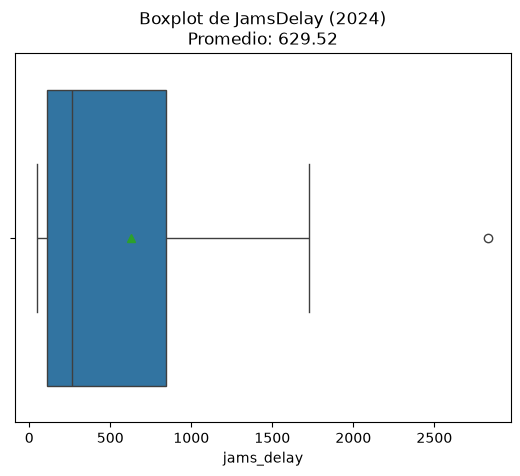

In [19]:
# Crear boxplot para observar el comportamiento de los minutos de congestion JamsDelay
# crea tu gráfico
sns.boxplot(data=merged, x='jams_delay',showmeans=True)
# obtener promedio para mostrarlo en título
mean_value = merged['jams_delay'].mean()
plt.title(f'Boxplot de JamsDelay (2024)\nPromedio: {mean_value:.2f}')
plt.show()

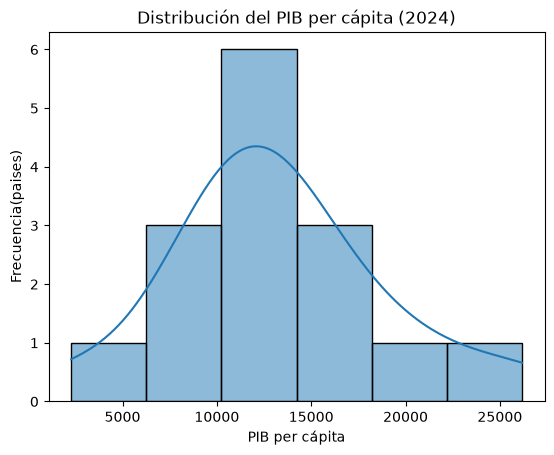

In [20]:
# Crear histograma para ver la distribución de la economía (city_gdp_capita)
sns.histplot(merged['city_gdp_capita'], kde=True)
plt.title('Distribución del PIB per cápita (2024)')
plt.xlabel('PIB per cápita')
plt.ylabel('Frecuencia(paises)')
plt.show()

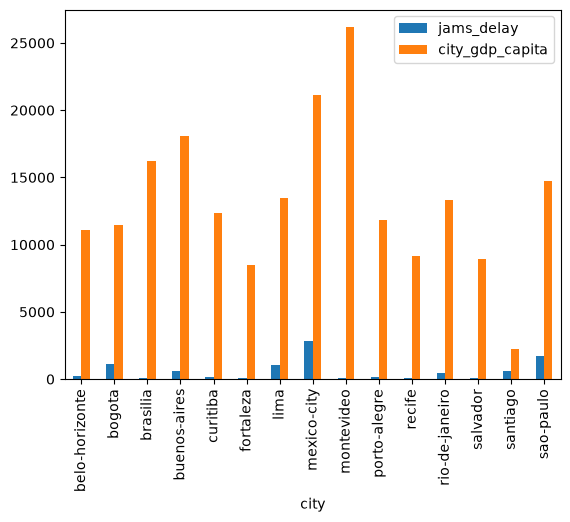

In [21]:
# Gráfico de barras para comparar jams_delay y city_gdp_capita por ciudad
merged.set_index('city').plot(kind='bar', y=['jams_delay', 'city_gdp_capita'])
plt.xticks(rotation=90)
plt.show()

**Tip**: Antes del plt.show() agrega el código plt.xticks(rotation=90) para rotar las etiquetas del eje X en 90 grados.

### 🧠 **Reflexiona**
Excelente trabajo llegando a esta etapa del análisis. Antes de avanzar, revisa tus gráficos, tómate un momento para pensar:

* ¿Las ciudades con mayor PIB per cápita también presentan más congestión?
* ¿O sucede lo contrario, o no existe una relación clara?

**Escribe tus comentarios**:
Se observa que las ciudades que tienen un mayor Producto Interno Bruto (PIB) no muestran más congestión, <br>no hay una correlación entre las variables de congestión<br> ni la del PIB. <br>Tampoco en la comparación entre las variables PIB per cápita y el retraso por tráfico (jams delay)<br> no se verifica correlación entre estas, en el caso de Montevideo que presenta el mayor PIB per cápita no es la más congestionada,<br> en Ciudad de Méjico se da el mayor nivel de embotellamientos. <br>Con todo esto se infiere que la congestión en el tráfico vehicular está más relacionada con la densidad poblacional,<br> factores en las infraestructuras de planeación urbana y en el transporte público.<br>



---

## 🧩Paso 7: Exportar y documentar resultados

En esta etapa final consolidarás todo tu trabajo: guardarás el dataset limpio y crearás un resumen que documente los resultados del proyecto.

### 7.1 Guardar dataset final

**🎯Objetivo:**
Generar un CSV limpio, reproducible y con columnas relevantes para análisis posterior.

**Instrucciones**

- Exporta el DataFrame `merged` con el nombre: `ladb_mobility_economy_2024_clean.csv`
- Usa `index=False` para no incluir el índice.

In [22]:
# Exporta el dataset final como CSV
merged.to_csv("ladb_mobility_economy_2024_clean.csv", index=False)

Para poder ver o descargar el archivo generado:   
En el menú lateral que esta a la izquierda, ve hasta la parte de abajo, a la sección de **Exportar dataset** para más información. 

---

## ✅ Entregables

1. **Notebook `.ipynb`** con todas las celdas (código + comentarios).
2. **CSV final**: `ladb_mobility_economy_2024_clean.csv`.
3. **Resumen ejecutivo breve** en Markdown (3–5 párrafos).



---

# 🧾 Resumen ejecutivo (plantilla)

> Completa este resumen al finalizar el análisis. Mantén 3–5 párrafos cortos, claros y accionables.

**Contexto y objetivo**<br>
El objetivo de este análisis es examinar la relación entre la congestión vehicular, medida mediante los retrasos registrados en jams_delay, <br>
y la productividad económica de las ciudades, representada por el PIB per cápita en dólares estadounidenses (city_gdp_capita). <br>
Comprender esta relación permite evaluar si las ciudades con mayores ingresos por habitante presentan una movilidad más eficiente o si los<br> 
problemas de congestión podrían representar un obstáculo para su desarrollo económico.<br>

**Cobertura de datos**
El estudio comprende el año 2024 e integra más de un millón de registros de tráfico recopilados en tiempo real en 387 ciudades de distintas<br>
 partes del mundo, junto con indicadores económicos de 30 grandes metrópolis. Esta integración permite comparar los indicadores de movilidad<br>
  y las condiciones económicas de las ciudades incluidas en ambas fuentes de información.<br>

**Metodología (alto nivel)**
1.	Limpieza y estandarización: Se normalizaron los nombres de las columnas mediante el formato snake_case, se corrigieron los tipos de datos<br>
 numéricos eliminando separadores de miles y símbolos porcentuales, y se transformaron las marcas temporales al formato datetime.<br> 
 Estas acciones facilitaron el procesamiento y la comparación de las variables.<br>
2.	Filtrado y agregación: Se seleccionaron los registros correspondientes al año 2024 y se calcularon los promedios anuales por ciudad.<br> 
Este procedimiento permitió resumir las variaciones diarias de la congestión y obtener indicadores comparables entre las ciudades analizadas<br>.
3.	Integración de las fuentes: Se realizó un INNER JOIN utilizando las columnas city y year como claves de unión, con el propósito de combinar<br>
 los datos de movilidad y economía en el DataFrame merged. De esta manera, se obtuvo una tabla consolidada para estudiar conjuntamente los<br> 
 retrasos por congestión y el PIB per cápita.<br>
4.	Validación visual: Se emplearon diagramas de caja (boxplots), histogramas y gráficos de barras para examinar la distribución de los datos,<br>
 identificar valores atípicos y comparar los niveles de congestión entre las ciudades incluidas en el conjunto final.<br>

**Hallazgos iniciales**<br>
•	Ausencia de una relación directa evidente: Los resultados iniciales no muestran un patrón claro que permita afirmar que un mayor PIB per<br><br>
 cápita se asocia necesariamente con menores retrasos por congestión. De igual manera, las ciudades con ingresos moderados o bajos no <br>
 presentan obligatoriamente los mismos niveles de tráfico. Esto sugiere que la relación entre movilidad y productividad económica podría estar<br>
  influida por otros factores, como la infraestructura vial, la planificación urbana y la disponibilidad de transporte público.<br>

•	Valores atípicos en los retrasos por congestión: Ciudad de Méjico destaca por registrar un promedio de jams_delay de 2.833,06 minutos,<br> 
mientras que Bogotá presenta un promedio de 1.141,55 minutos. Dado que jams_delay está medido en minutos, estos valores representan <br>
magnitudes temporales importantes que merecen un análisis adicional. Sin embargo, antes de interpretarlos como tiempo perdido por un conductor <br>
o como retraso por trayecto, es necesario confirmar si la variable expresa minutos acumulados por registro, por día o durante otro intervalo <br>
de observación.<br>
•	Contrastes en las ciudades latinoamericanas: Montevideo, con un PIB per cápita aproximado de 26.200 USD, presenta niveles de congestión<br>
 reducidos dentro de la muestra, mientras que Bogotá y Lima muestran demoras importantes. En el caso de Bogotá, el promedio registrado de <br>
 jams_delay es de 1.141,55 minutos. Estas diferencias evidencian que los niveles de ingreso no explican por sí solos el comportamiento del <br>
 tráfico y que resulta necesario considerar otros elementos relacionados con la movilidad y la organización urbana.<br>

**Recomendaciones**<br>
Se recomienda evaluar mejoras en el transporte público y en la gestión del tráfico de Bogotá, Lima y Ciudad de Méjico, de acuerdo con <br>
las necesidades particulares de cada ciudad. Entre las medidas posibles se encuentran la optimización de semáforos, el monitoreo <br>
en tiempo real y la mejora de los corredores viales.<br>
Como siguiente paso, se debe validar cómo se calcula jams_delay y analizar la correlación entre esta variable y el PIB per cápita. <br>
Incorporar variables adicionales, como la densidad poblacional y el parque automotor, permitirá profundizar en los factores asociados a la <br>
congestión y fundamentar mejor las recomendaciones.<br>
<br>